In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize
import scipy.io


## Plot raster plot

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_94060/1869238114.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / fs)}' for x_tick in x_ticks], fontsize=14)


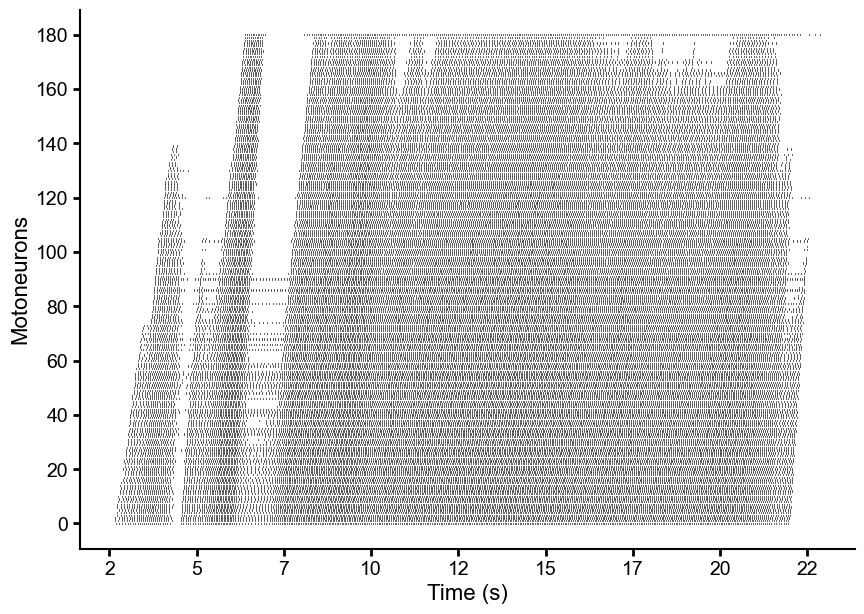

In [2]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S2_alltrials/Day02/DR_S2_Day02_trial02.jld2"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]

n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5  # Thinner raster lines
horizontal_offset = 100
fs = 20000  # Sampling rate

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset],
                    [neuron - line_height / 2, neuron + line_height / 2],
                    color='black', linewidth=line_thickness)

# Axis labels and title
ax.set_xlabel("Time (s)", fontsize=16)
ax.set_ylabel("Motoneurons", fontsize=16)

# Format x-ticks: convert from samples to seconds (assuming 20 kHz)
x_ticks = ax.get_xticks()
ax.set_xticklabels([f'{int(x_tick / fs)}' for x_tick in x_ticks], fontsize=14)

# Set y-ticks every 20 motoneurons
ax.set_yticks(np.arange(0, n_neurons + 1, 20))
ax.set_yticklabels(np.arange(0, n_neurons + 1, 20), fontsize=14)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Style bottom and left spines
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['left'].set_linewidth(1.5)

# Tick appearance
ax.tick_params(axis='both', direction='out', length=5, width=2)

# Save and show
# plt.savefig('/Users/nmt121/Desktop/Figures/Rasters/Raster_day14_S1.pdf', dpi=300, bbox_inches='tight')
plt.show()



## Plot firing rates

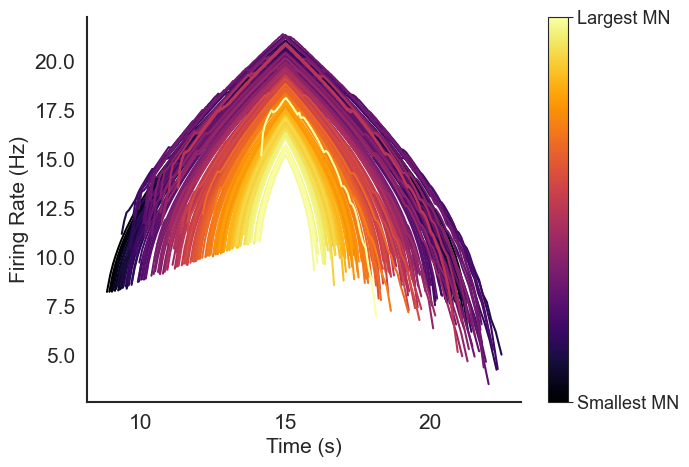

In [8]:
# Load firing rates
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firingrates/allrates_constant.jld2"
with h5py.File(file_path, 'r') as f:
    all_rates = f['new_all_rates'][:]

# Load timebases
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firingrates/alltimebases_constant.jld2"
with h5py.File(file_path, 'r') as f:
    all_timebases = f['new_all_bases'][:]

# Create a color map
cmap = plt.get_cmap('inferno')
discrete_cmap = cmap(np.linspace(0, 1, all_timebases.shape[1]))

# Normalize color map
norm = Normalize(vmin=0, vmax=88)

# Create figure
fig, ax = plt.subplots(figsize=(7, 5))

# Plot firing rate traces
for i in range(all_timebases.shape[1]):
    ax.plot(all_timebases[:, i], all_rates[:, i], color=discrete_cmap[i], linewidth=1.5)

# Axis labels
ax.set_xlabel("Time (s)", fontsize=15, fontname='Arial')
ax.set_ylabel("Firing Rate (Hz)", fontsize=15, fontname='Arial')

# Remove title
ax.set_title("")

# Tick settings
ax.tick_params(axis='both', length=5)
plt.xticks(fontsize=15, fontname='Arial')
plt.yticks(fontsize=15, fontname='Arial')

# Clean up axes
ax.grid(False)
sns.despine()
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['left'].set_linewidth(1.5)

# Color bar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax)
cbar.set_ticks([0, 88])
cbar.set_ticklabels(['Smallest MN', 'Largest MN'])
cbar.ax.tick_params(labelsize=13)
for label in cbar.ax.get_yticklabels():
    label.set_fontname('Arial')
x_ticks = ax.get_xticks()

# Save the figure in high quality
# plt.savefig('/Users/nmt121/Desktop/Figures/constantinh.pdf', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


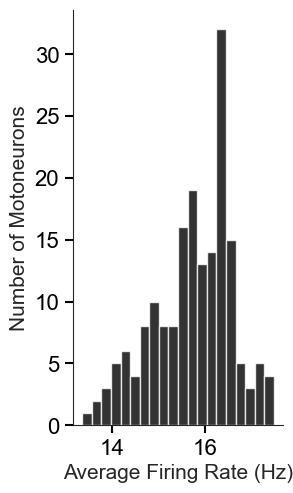

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# === Compute average firing rate per neuron ===
avg_firing_rates = np.nanmean(all_rates, axis=0)  # shape: (n_neurons,)

# === Plot histogram ===
plt.figure(figsize=(3, 5))
plt.hist(avg_firing_rates, bins=20, color='black', edgecolor='white', alpha=0.8)

# === Styling ===
plt.xlabel('Average Firing Rate (Hz)', fontsize=15, fontname='Arial')
plt.ylabel('Number of Motoneurons', fontsize=15, fontname='Arial')
plt.xticks(fontsize=16, fontname='Arial')
plt.yticks(fontsize=16, fontname='Arial')

sns.despine()
plt.tight_layout()
ax = plt.gca()

ax.tick_params(
    axis='both',        # apply to both x and y axes
    which='major',      # major ticks only
    direction='out',    # or 'inout' for both sides
    length=6,           # length of the ticks
    width=1.5,          # thickness of the ticks
    colors='black',     # color of tick lines
    bottom=True,left=True,   # ensure all sides have ticks
)
# === Optional: Save figure ===
plt.savefig('/Users/nmt121/Desktop/Figures/avg_firing_rate_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()


## Plot firing rate stace space plot of different pairs

In [ ]:

def load_trajectory(filepath):
    with h5py.File(filepath, 'r') as f:
        return f['avg_traj'][:].T

# Load the three trajectories
traj1 = load_trajectory("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair34_constant.jld2")
traj2 = load_trajectory("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair170_constant.jld2")
traj3 = load_trajectory("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair6667_constant.jld2")

# Plot settings
plt.rcParams['font.family'] = 'Arial'
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

trajectories = [traj1, traj2, traj3]
colors = ['darkorange', 'purple', 'green']
titles = ['Pair 131–134', 'Pair 170–171', 'Pair 66–67']  # Optional titles

for i, ax in enumerate(axs):
    traj = trajectories[i]
    ax.plot(traj[:, 0], traj[:, 1], color=colors[i], linewidth=2)

    ax.set_xlim([-1, 20])
    ax.set_ylim([-1, 20])

    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_yticks([0, 5, 10, 15, 20])
    ax.tick_params(axis='both', labelsize=20,length=5)  # Make tick numbers larger
    
    ax.set_xlabel("FR low-threshold MN (Hz)", fontsize=25, fontname='Arial')
    if i == 0:
        ax.set_ylabel("FR high-threshold MN (Hz)", fontsize=25, fontname='Arial')
    # else:
    #     ax.set_yticklabels([])  # Hide Y ticks on other plots
    
    sns.despine(ax=ax)
    for side in ['bottom', 'left', 'top', 'right']:
        ax.spines[side].set_linewidth(2)
        


# Optional: add titles above subplots
# for i, ax in enumerate(axs):
#     ax.set_title(titles[i], fontsize=14, fontname='Arial')

plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/Figures/statespace_3pairs_constant.pdf', dpi=300, bbox_inches='tight')
plt.show()


NameError: name 'session_files1' is not defined

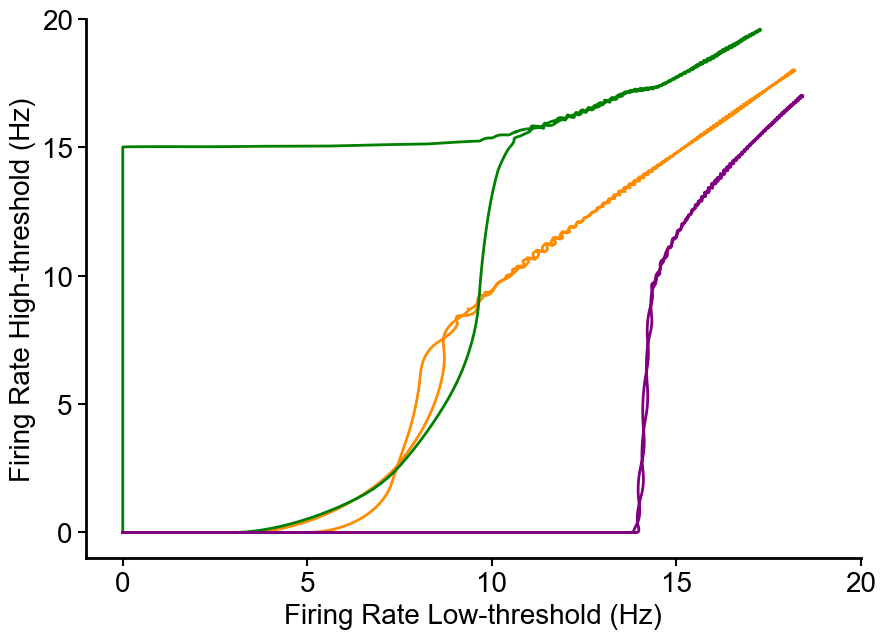

In [207]:


# Load data
file_path_sim = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair34_balanced.jld2"
with h5py.File(file_path_sim, 'r') as f:
    firings_similar = f['avg_traj'][:].T

file_path_diff = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair6667_balanced.jld2"
with h5py.File(file_path_diff, 'r') as f:
    firings_diff = f['avg_traj'][:].T
    
file_path_diff = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair170_balanced.jld2"
with h5py.File(file_path_diff, 'r') as f:
    firings_recr = f['avg_traj'][:].T

# Plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

# Plot trajectories with thinner lines
plt.plot(firings_similar[:, 0], firings_similar[:, 1], c='darkorange', linewidth=2)
plt.plot(firings_diff[:, 0], firings_diff[:, 1], c='green', linewidth=2)
plt.plot(firings_recr[:, 0], firings_recr[:, 1], c='purple', linewidth=2)

# Axis limits
plt.xlim([-1, 20])
plt.ylim([-1, 20])

# Axis labels (not bold)
ax.set_xlabel("Firing Rate Low-threshold (Hz)", fontsize=20, fontname='Arial')
ax.set_ylabel("Firing Rate High-threshold (Hz)", fontsize=20, fontname='Arial')

# Custom ticks with visible tick marks
plt.xticks([0, 5, 10, 15, 20], fontsize=20, fontname='Arial')
plt.yticks([0, 5, 10, 15, 20], fontsize=20, fontname='Arial')
ax.tick_params(axis='both', length=6, width=1.5, direction='out')

# Clean spines
sns.despine()
for side in ['bottom', 'left', 'top', 'right']:
    ax.spines[side].set_linewidth(2)

# No grid or title
ax.grid(False)
ax.set_title("")

# Save figure
plt.savefig('/Users/nmt121/Desktop/Figures/pairssin__balanced.pdf', dpi=300, bbox_inches='tight')
plt.show()

plt.show()


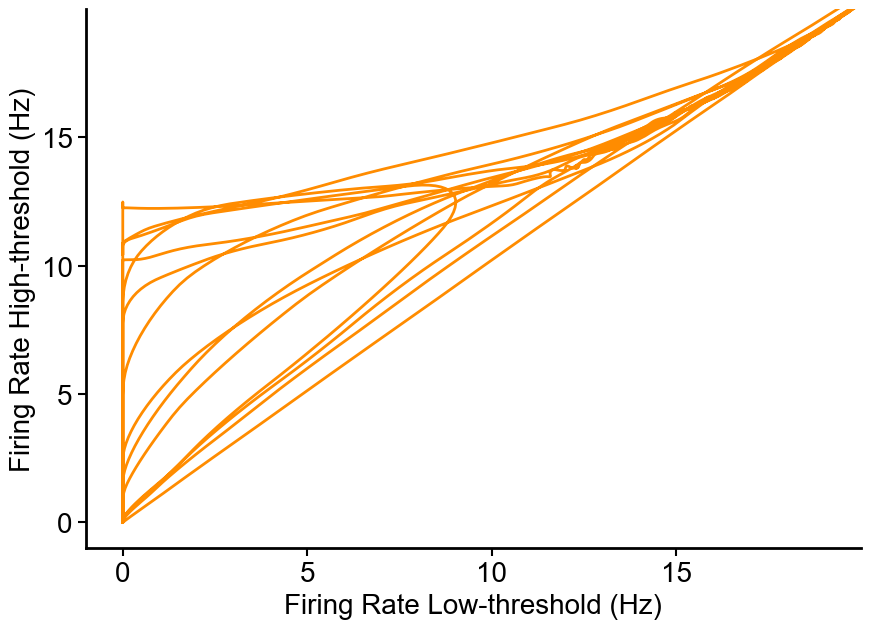

In [8]:


# Load data
file_path_sim = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/pairs_state_space/pair130131_firstday.jld2"

with h5py.File(file_path_sim, 'r') as f:
    firings = f['avg_traj'][:].T



# Plot settings
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

# Plot trajectories with thinner lines
plt.plot(firings[:, 0], firings[:, 1], c='darkorange', linewidth=2)


# Axis limits
plt.xlim([-1, 20])
plt.ylim([-1, 20])

# Axis labels (not bold)
ax.set_xlabel("Firing Rate Low-threshold (Hz)", fontsize=20, fontname='Arial')
ax.set_ylabel("Firing Rate High-threshold (Hz)", fontsize=20, fontname='Arial')

# Custom ticks with visible tick marks
plt.xticks([0, 5, 10, 15], fontsize=20, fontname='Arial')
plt.yticks([0, 5, 10, 15], fontsize=20, fontname='Arial')
ax.tick_params(axis='both', length=6, width=1.5, direction='out')

# Clean spines
sns.despine()
for side in ['bottom', 'left', 'top', 'right']:
    ax.spines[side].set_linewidth(2)

# No grid or title
ax.grid(False)
ax.set_title("")

# Save figure
plt.savefig('/Users/nmt121/Desktop/Figures/pair1.pdf', dpi=300, bbox_inches='tight')
plt.show()

plt.show()


## Plot force-tracking

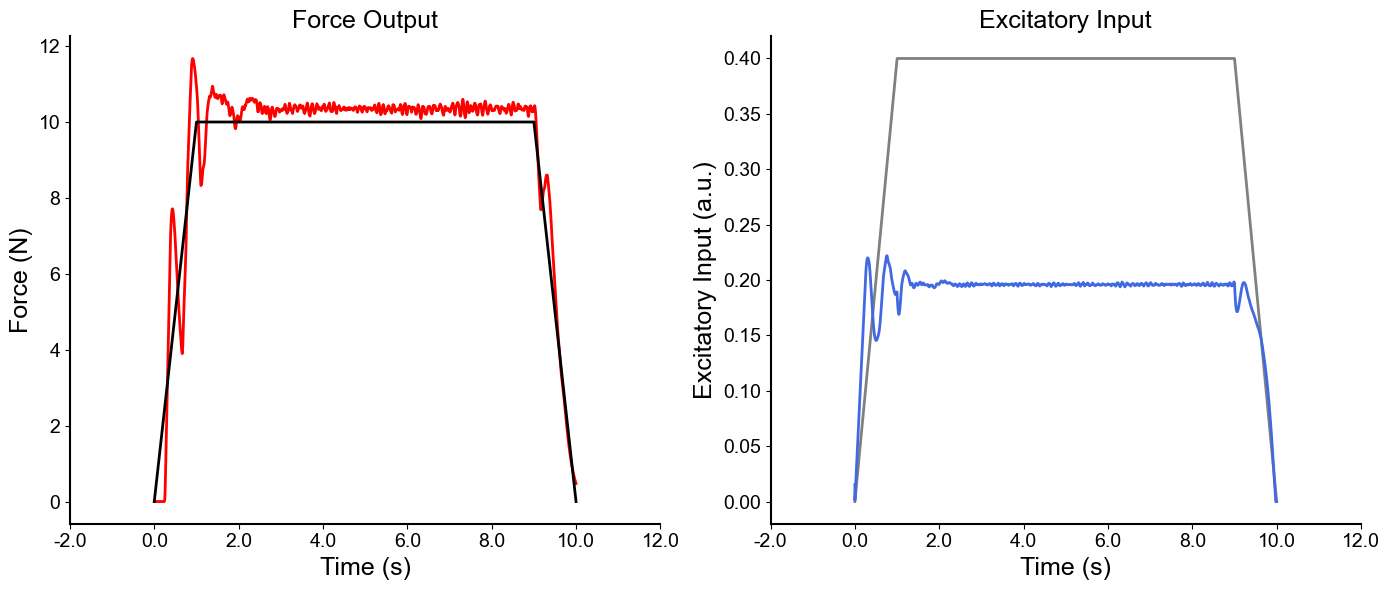

In [96]:
# Load data
with h5py.File("Data_MN_Model/Data_final/Forcetracking/controlled_force_trapezoid.jld2", 'r') as f:
    controlled_force = f['trajectory2_controlled'][:]

with h5py.File("Data_MN_Model/Data_final/Forcetracking/ideal_force_trapezoid.jld2", 'r') as f:
    ideal_force = f['ideal_force'][:]

with h5py.File("Data_MN_Model/Data_final/Forcetracking/newexc_trapezoid.jld2", 'r') as f:
    newexc = f['tr_new'][:]

with h5py.File("Data_MN_Model/Data_final/Forcetracking/originalexc_trapezoid.jld2", 'r') as f:
    originalexc = f['tr'][:]

# Set font
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'normal'

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Plot force (left)
ax1.plot(controlled_force, color='red', linewidth=2, label='Controlled')
ax1.plot(ideal_force, color='black', linewidth=2, label='Ideal')
ax1.set_xlabel("Time (s)", fontsize=18)
ax1.set_ylabel("Force (N)", fontsize=18)
ax1.tick_params(axis='both', labelsize=14, direction='out')
ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels([f"{x/1000:.1f}" for x in ax1.get_xticks()])
ax1.grid(False)
ax1.set_title("Force Output", fontsize=18)

# Clean spines (left plot)
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)
for spine in ['bottom', 'left']:
    ax1.spines[spine].set_linewidth(1.5)

# Plot excitation (right)
ax2.plot(originalexc, color='gray', linewidth=2, label='Original')
ax2.plot(newexc, color='royalblue', linewidth=2, label='Optimized')
ax2.set_xlabel("Time (s)", fontsize=18)
ax2.set_ylabel("Excitatory Input (a.u.)", fontsize=18)
ax2.tick_params(axis='both', labelsize=14, direction='out')
ax2.set_xticks(ax2.get_xticks())
ax2.set_xticklabels([f"{x/1000:.1f}" for x in ax2.get_xticks()])
ax2.grid(False)
ax2.set_title("Excitatory Input", fontsize=18)
x_ticks = ax.get_xticks()

# Clean spines (right plot)
for spine in ['top', 'right']:
    ax2.spines[spine].set_visible(False)
for spine in ['bottom', 'left']:
    ax2.spines[spine].set_linewidth(1.5)

# Tight layout and save
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/Figures/forcetracking_trapezoid.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()


## Plot accuracy of the optmization process

In [ ]:
# Data points
group1 = np.array([0.93, 0.69, 0.76, 0.95, 0.96, 0.75, 0.98, 0.76])
group2 = np.array([0.9, 0.94, 0.96, 0.96, 0.96, 0.97, 0.91, 0.9])

# Combine data for violin plot
data = [group1, group2]

# Labels for the groups
labels = ['TA', 'VL']

# Plotting
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(10, 7))

# Create the violin plot
sns.violinplot(data=data, palette='Pastel1', inner=None, linewidth=2)

# Overlay individual data points (larger dots: s=60)
for i, group in enumerate(data):
    jittered_x = np.random.normal(i, 0.05, size=len(group))
    plt.scatter(jittered_x, group, color='gray', zorder=50, s=60)

# Overlay mean and standard deviation (larger mean marker: s=120)
for i, group in enumerate(data):
    mean = np.mean(group)
    std  = np.std(group)
    plt.scatter(i, mean, color='black', zorder=11,
                s=120, label='Mean ± SD' if i == 0 else None)
    plt.errorbar(i, mean, yerr=std, fmt='none',
                 ecolor='black', capsize=5, zorder=20)

# Customize axis labels and appearance
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=18, fontweight='bold')
ax.set_ylabel('R$^2$', fontsize=20, fontweight='bold')

# Hide grid and set line widths
ax.grid(False)
sns.despine()
ax.tick_params(axis='both', length=0)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Set y-limits for better visibility
plt.ylim(0, 1.2)

# Save and show the plot
plt.savefig('/Users/nmt121/Desktop/trial.pdf', dpi=300, bbox_inches='tight')
plt.show()


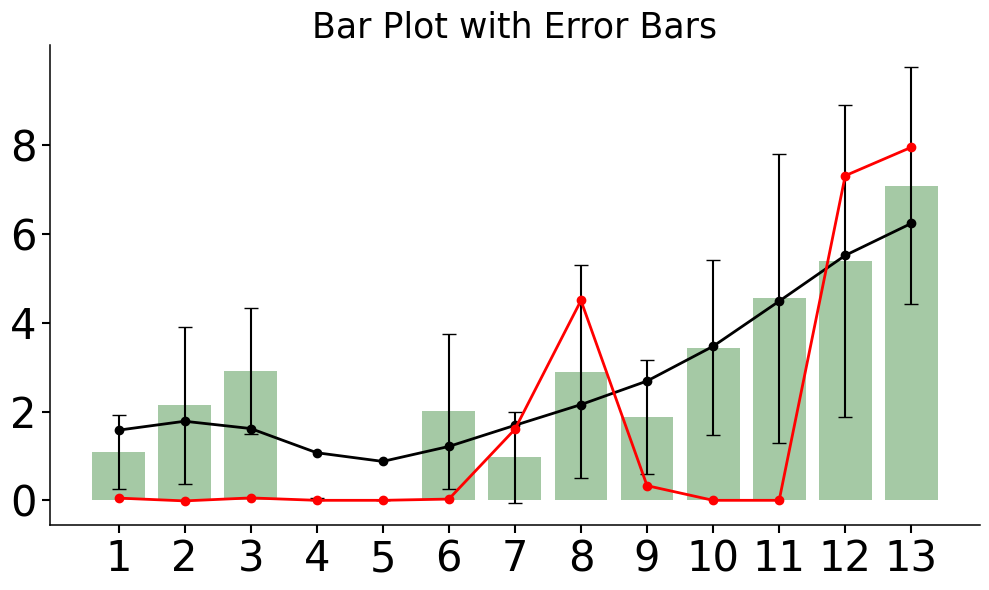

In [ ]:

from scipy.ndimage import gaussian_filter1d

# Data
df = pd.read_csv('Data_MN_Model/Data_final/metrics_decorrelation_time_Brackleinsubejcts/S1_results_metrics.csv')
x_values=(np.array(df['Mean']))
error_bars=(np.array(df['Std']))

# x_values[2]=0
# error_bars[2]=0

# Set up figure and single subplot
fig, ax = plt.subplots(figsize=(10, 6))

# Bar plot with error bars
indices = np.arange(len(x_values))
bars = ax.bar(indices, x_values, yerr=error_bars, capsize=5,
               color='#8FBC8F', alpha=0.8)

# Optionally, plot a smoothed line over the bars
smoothed_values = gaussian_filter1d(x_values, sigma=1.2)
ax.plot(indices, smoothed_values, marker='o', linestyle='-', color='black', linewidth=2)

# Title
ax.set_title("Bar Plot with Error Bars", fontsize=25)

# X-axis
ax.set_xticks(indices)
ax.set_xticklabels(range(1, len(x_values) + 1), fontsize=30, rotation=0)
ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=30)

# Y-axis: only integer ticks
# y_ticks = ax.get_yticks()
# y_ticks_int = [int(t) for t in y_ticks if np.isclose(t, round(t))]
# ax.set_yticks(y_ticks_int)
# ax.set_yticklabels([str(t) for t in y_ticks_int], fontsize=25)
ax.set_yticks(np.arange(0, 10, 2))  # Creates ticks from -2 to 8 with step size of 2
scatter_values = [0.05, -0.013, 0.054, 0, 0,0.028, 1.6, 4.5, 0.33, 0, 0, 7.31, 7.95]  # Scatter line values
# scatter_values2 = [-0.0369, 0,0.04,0.015,0,0.01,1.73,4.54,0.5,0.05,0,7.85]  # Scatter line values

ax.plot(indices[:len(scatter_values)], scatter_values, marker='o', color='red', linestyle='-', linewidth=2)
# ax.plot(indices[:len(scatter_values)-1], scatter_values2, marker='o', color='orange', linestyle='-', linewidth=2)

# Axes spines and line width
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(1.10)
    



# Final layout
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/simulated1.pdf', dpi=300, bbox_inches='tight')
plt.show()


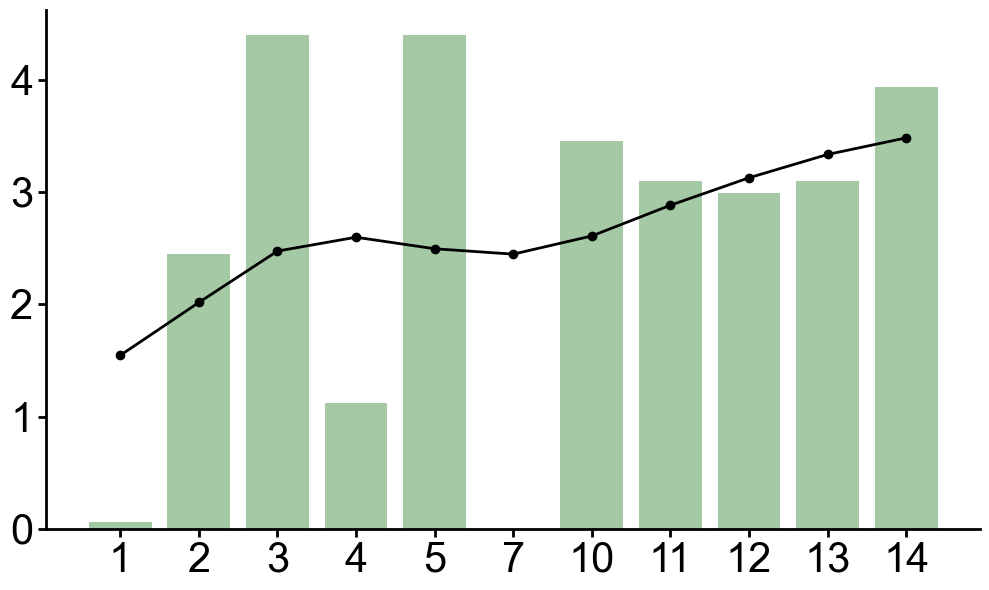

In [ ]:


# Set global font to Arial
plt.rcParams['font.family'] = 'Arial'

# Actual x-tick labels (non-uniform)
# x_labels = [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
# x_labels = [2,3,4,7,13]
x_labels = [1,2,3,4,5,7,10,11,12,13,14]
# x_labels = [1,3,7,8,9,10,11,12,13,14]

# x_labels = [1,3,4,5,6,7,8,9,10,11,12,13,14]
# x_labels = [1,2,3,4,5,6,7,8,9,10]

# y_values = [1, 2.21, 3.38, 0.06, 3.2, 2.1, 2, 4.4, 0.54, 4.6, 2.29, 3.18, 3.7]
# y_values = [0.05,2.65,0.8,2.6,3.87]
y_values = [0.06,2.45,4.4,1.12,4.4,0,3.45,3.1,2.99,3.1,3.93]
# y_values = [0.045,0.87,0.07,0.4,2.63,0.1,1.4,1.4,2.4,2.6]
# y_values = [0.02,0.88,0,0,3.96,0.08,1.1,4.1,5.5,5.9]
# y_values = [0,7.9,0,0.7,0,0,5,2.7,3.8,6,0,3.7,6.8]
# y_values = [0,0,0.83,2.22,2.13,0,2.8,3.88,1.37,0.2]


x_positions = np.arange(len(y_values))

# Gaussian smoothing
smoothed_values = gaussian_filter1d(y_values, sigma=1.5)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(x_positions, y_values, capsize=5, color='#8FBC8F', alpha=0.8)

# Smoothed line
ax.plot(x_positions, smoothed_values, color='black', marker='o', linestyle='-', linewidth=2)

# X-ticks and labels
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, fontsize=30)
ax.tick_params(axis='both', which='major', width=2, length=6, labelsize=30)

# Set axis line widths
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# Optional legend

# Layout and save
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/Figures/Decorrelation_time_simulated3.pdf', dpi=300, bbox_inches='tight')
plt.show()


## Plot accuracy of the optimization

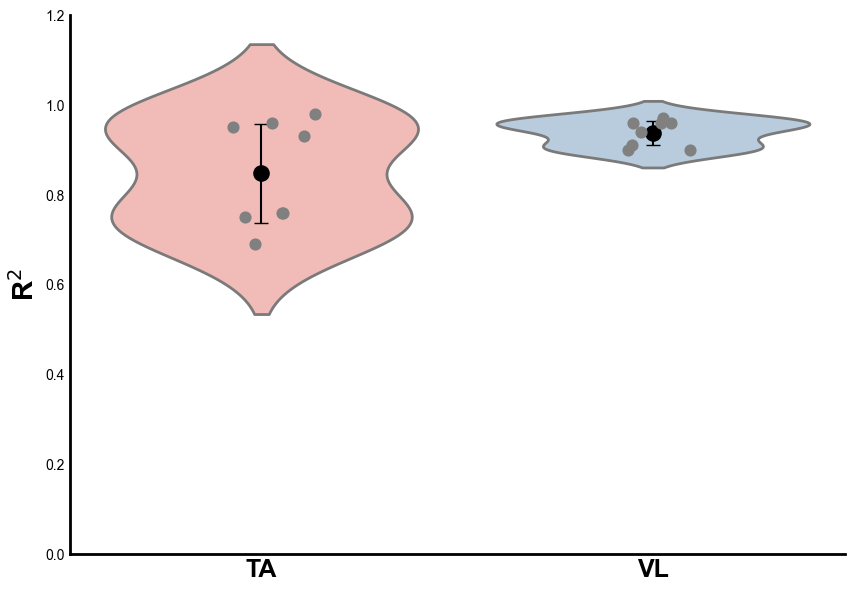

In [ ]:
# Data points
group1 = np.array([0.93, 0.69, 0.76, 0.95, 0.96, 0.75, 0.98, 0.76])
group2 = np.array([0.9, 0.94, 0.96, 0.96, 0.96, 0.97, 0.91, 0.9])

# Combine data for violin plot
data = [group1, group2]

# Labels for the groups
labels = ['TA', 'VL']

# Plotting
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(10, 7))

# Create the violin plot
sns.violinplot(data=data, palette='Pastel1', inner=None, linewidth=2)

# Overlay individual data points (larger dots: s=60)
for i, group in enumerate(data):
    jittered_x = np.random.normal(i, 0.05, size=len(group))
    plt.scatter(jittered_x, group, color='gray', zorder=50, s=60)

# Overlay mean and standard deviation (larger mean marker: s=120)
for i, group in enumerate(data):
    mean = np.mean(group)
    std  = np.std(group)
    plt.scatter(i, mean, color='black', zorder=11,
                s=120, label='Mean ± SD' if i == 0 else None)
    plt.errorbar(i, mean, yerr=std, fmt='none',
                 ecolor='black', capsize=5, zorder=20)

# Customize axis labels and appearance
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=18, fontweight='bold')
ax.set_ylabel('R$^2$', fontsize=20, fontweight='bold')

# Hide grid and set line widths
ax.grid(False)
sns.despine()
ax.tick_params(axis='both', length=0)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Set y-limits for better visibility
plt.ylim(0, 1.2)

# Save and show the plot
plt.savefig('/Users/nmt121/Desktop/trial.pdf', dpi=300, bbox_inches='tight')
plt.show()


## Plot distribution of hyseresis in experimental and simulated data

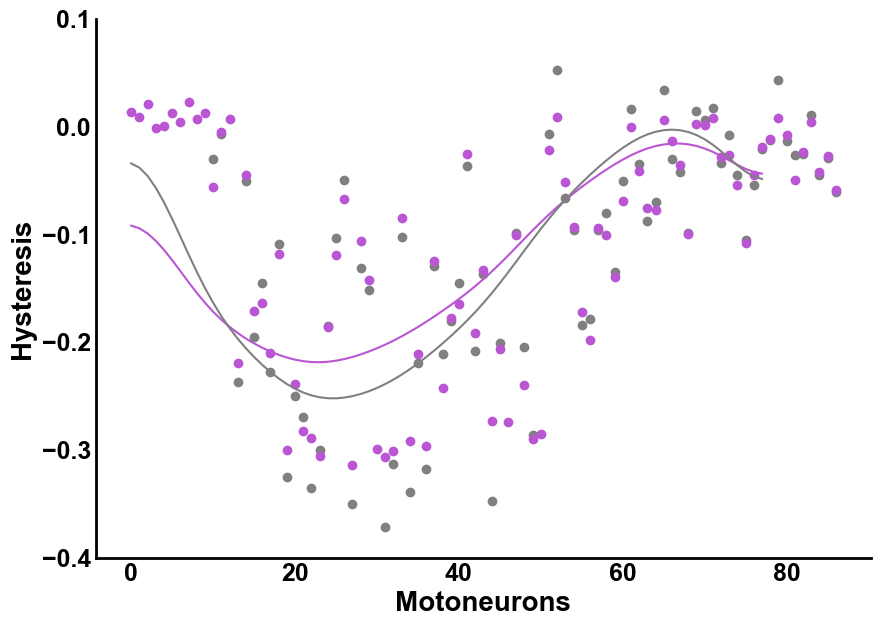

In [ ]:

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA_exp.jld2" 

with h5py.File(file_path, 'r') as f:
    exp_hyst = f['hyst_exp'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/hysteresis_TA.jld2"

with h5py.File(file_path, 'r') as f:
    sim_hyst = f['hysteresis'][:]
    
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_sim.jld2"

with h5py.File(file_path, 'r') as f:
    polys = f['y_fit_hysteresis_s'][:]
    
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/polyfitTA_exp.jld2"

with h5py.File(file_path, 'r') as f:
    polye = f['y_fit_hysteresis'][:]
    
    
    
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

plt.scatter(range(0,87),exp_hyst,c='gray')
plt.scatter(range(0,87),sim_hyst[:,0],c='mediumorchid')
plt.plot(gaussian_filter1d(polys,sigma=4),c='mediumorchid')
plt.plot(gaussian_filter1d(polye,sigma=4),c='gray')

# Set axis labels
ax.set_xlabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_ylabel("Hysteresis",fontsize=20, fontweight='bold')
# ax.set_title("",fontsize=20, fontweight='bold')


# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')
plt.ylim([-0.005,0.1])
# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  
plt.ylim(-0.4,0.1)
# plt.legend(['Experimental','Simulated'],fontsize=15)
# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/PolyFit_TA_nolegend.pdf', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()

    

## Plot new VthCa values for each subject

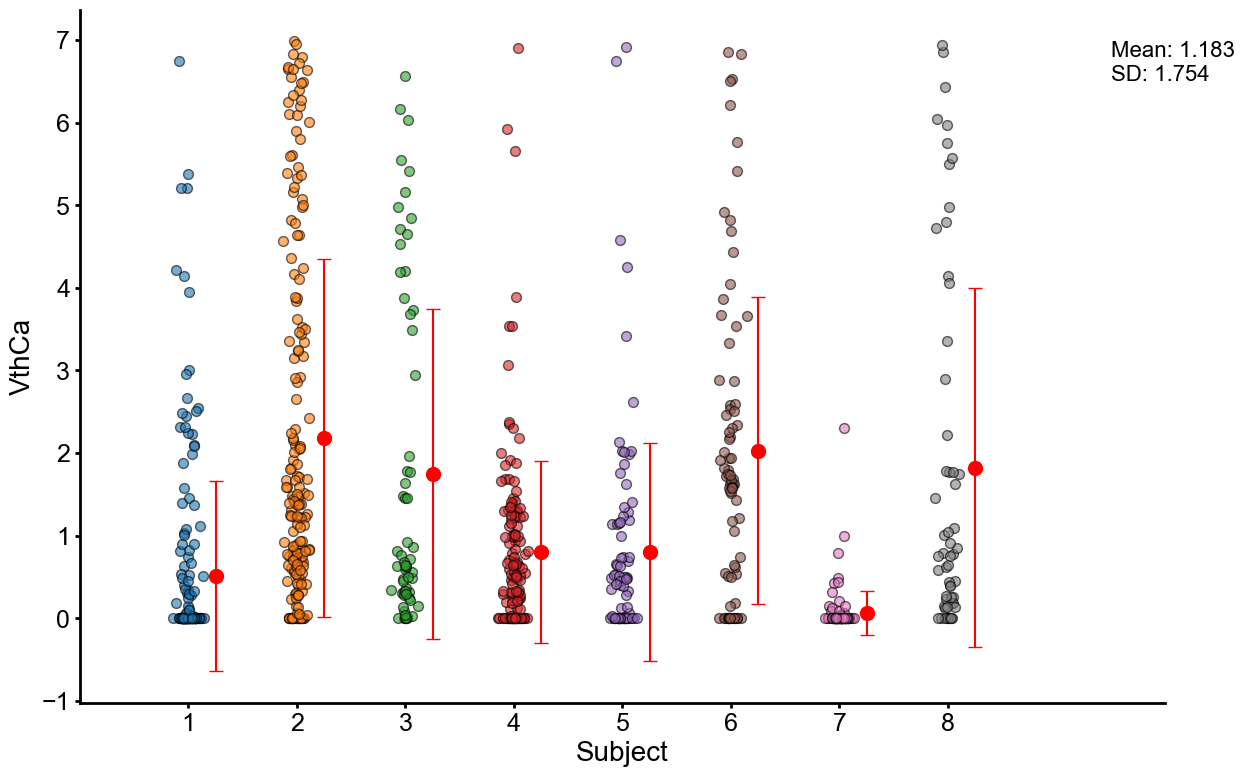

In [ ]:
# Define file paths for each subject
base_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/"
subjects = [f"VthCa_TA_subject{i}_gamma1.jld2" for i in range(1, 9)]

# Load all data into a dictionary
data_dict = {}

# Load data
for i, file_name in enumerate(subjects, start=1):
    file_path = f"{base_path}{file_name}"
    with h5py.File(file_path, 'r') as f:
        data = f['VthCa_newTA'][:]
        data_dict[f'subject{i}'] = data[:, 0]

# Flatten all values to compute overall mean and std
all_values = np.concatenate(list(data_dict.values()))
overall_mean = np.mean(all_values)
overall_std = np.std(all_values)

# Plot settings
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(14, 9))

# Plot scatter and subject-wise mean with std
for i, (key, values) in enumerate(data_dict.items(), start=1):
    jitter = np.random.normal(0, 0.05, size=len(values))
    ax.scatter([i] * len(values) + jitter, values, alpha=0.6, edgecolors='k', s=50)
    
    # Compute subject-wise mean and std
    subj_mean = np.mean(values)
    subj_std = np.std(values)
    
    # Plot the mean as a larger point slightly offset to the right
    ax.errorbar(i + 0.25, subj_mean, yerr=subj_std, fmt='o', color='red',
                markersize=10, capsize=5, label='Subject Mean' if i == 1 else None)

# Set axis labels
ax.set_xlabel("Subject", fontsize=20)
ax.set_ylabel("VthCa", fontsize=20)

# Format the axes
ax.tick_params(axis='both', which='major', labelsize=18, width=2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(range(1, len(subjects) + 1))
ax.set_xlim([0, len(subjects) + 2])

# Add overall mean and std text
text_x_pos = len(subjects) + 1.5
text_y_pos = np.max(all_values)
ax.text(text_x_pos, text_y_pos, f"Mean: {overall_mean:.3f}\nSD: {overall_std:.3f}",
        fontsize=16, ha='left', va='top', fontweight='normal', family='Arial')

sns.despine()

# Save and show
plt.savefig('/Users/nmt121/Desktop/vthcavalues.pdf', dpi=300, bbox_inches='tight')
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_15105/207805002.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool', new.shape[1])


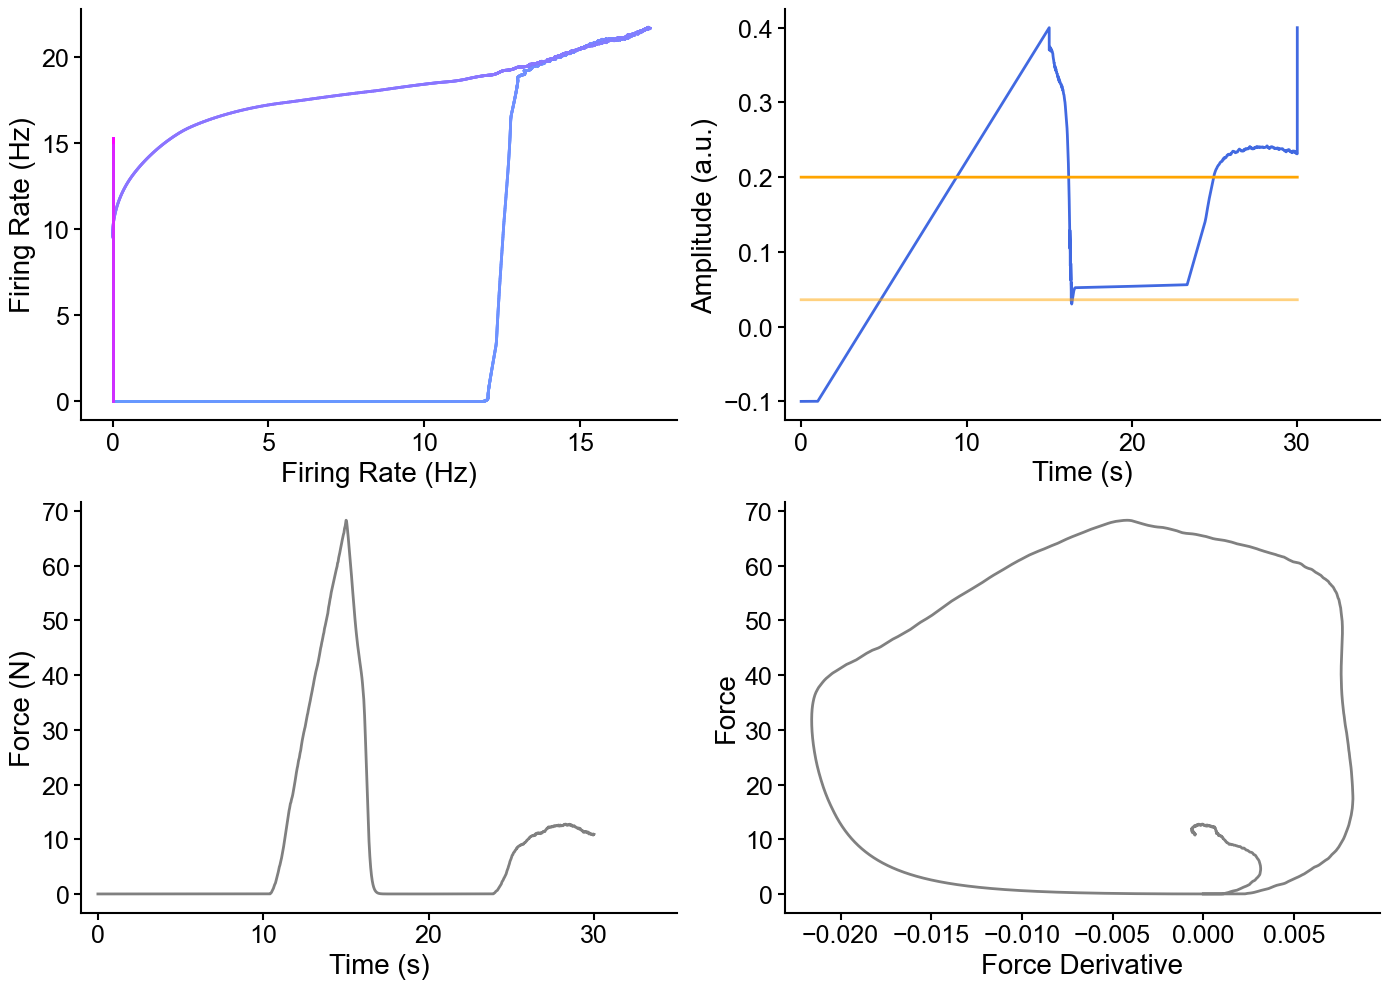

In [ ]:

# Set font globally
plt.rcParams['font.family'] = 'Arial'

# Load files
with h5py.File("Data_MN_Model/Data_final/Controller_FINAL_results/exc_TA_MN7087_constant.jld2", 'r') as f:
    exc1 = f['tr_new'][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/force_TA_MN7087_constant.jld2", 'r') as f:
    force = f['force'][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/inh_TA_MNMN7087_constant.jld2", 'r') as f:
    inh = f['inh_input'][:]

with h5py.File("Data_MN_Model/Data_final/Controller_FINAL_results/trajectory_controlled_TA_MN7087_constant.jld2", 'r') as f:
    new = f['trajectory2_controlled'][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/force_derivative_TA_MN7087_constant.jld2", 'r') as f:
    force_derivative = f['force_derivative'][:]

# Create 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
cmap = cm.get_cmap('cool', new.shape[1])

# Plot 1: Trajectory in firing rate space
for i in range(new.shape[1] - 1):
    axs[0, 0].plot(new[0, i:i+2], new[1, i:i+2], color=cmap(i / new.shape[1]), linewidth=2)

axs[0, 0].set_xlabel("Firing Rate (Hz)", fontsize=20)
axs[0, 0].set_ylabel("Firing Rate (Hz)", fontsize=20)
axs[0, 0].tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5, labelcolor='black')
axs[0, 0].set_xlim(left=-1)
axs[0, 0].set_xlim(right=20)
axs[0, 0].grid(False)

# Plot 2: Excitation and Inhibition
axs[0, 1].plot(exc1, color='royalblue', linewidth=2)
axs[0, 1].plot(inh * 0.18, color='orange', linewidth=2, alpha=0.5)
axs[0, 1].plot(inh, color='orange', linewidth=2)
axs[0, 1].set_xlabel("Time (s)", fontsize=20)
axs[0, 1].set_ylabel("Amplitude (a.u.)", fontsize=20)
axs[0, 1].tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5, labelcolor='black')
axs[0, 1].set_xticks(axs[0, 1].get_xticks())
axs[0, 1].set_xticklabels([f'{int(x / 1000)}' for x in axs[0, 1].get_xticks()], fontsize=18)
axs[0, 1].set_xlim(-1000, 35000)
axs[0, 1].grid(False)

# Plot 3: Force
axs[1, 0].plot(force, color='gray', linewidth=2)
axs[1, 0].set_xlabel("Time (s)", fontsize=20)
axs[1, 0].set_ylabel("Force (N)", fontsize=20)
axs[1, 0].tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5, labelcolor='black')
axs[1, 0].set_xticks(axs[1, 0].get_xticks())
axs[1, 0].set_xticklabels([f'{int(x / 20000)}' for x in axs[1, 0].get_xticks()], fontsize=18)
axs[1, 0].set_xlim(-20000, 700000)
axs[1, 0].set_ylim(top=80)
axs[1, 0].grid(False)

# Plot 4: Force vs. Force Derivative
sigma = 8000
smoothed_force_derivative = gaussian_filter1d(force_derivative[0:599999], sigma=sigma)
axs[1, 1].plot(smoothed_force_derivative, force[1:600000], color='gray', linewidth=2)
axs[1, 1].set_xlabel("Force Derivative", fontsize=20)
axs[1, 1].set_ylabel("Force", fontsize=20)
axs[1, 1].tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5, labelcolor='black')
axs[1, 1].grid(False)

# Apply final styling
for ax in axs.flat:
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['left'].set_linewidth(1.5)
    for tick in ax.get_xticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('normal')
    for tick in ax.get_yticklabels():
        tick.set_fontsize(18)
        tick.set_fontweight('normal')

# Final layout and save
plt.tight_layout()
sns.despine()
# plt.savefig('/Users/nmt121/Desktop/constantpair4551.pdf', dpi=300, bbox_inches='tight')
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_30703/4147148889.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool', new.shape[1])


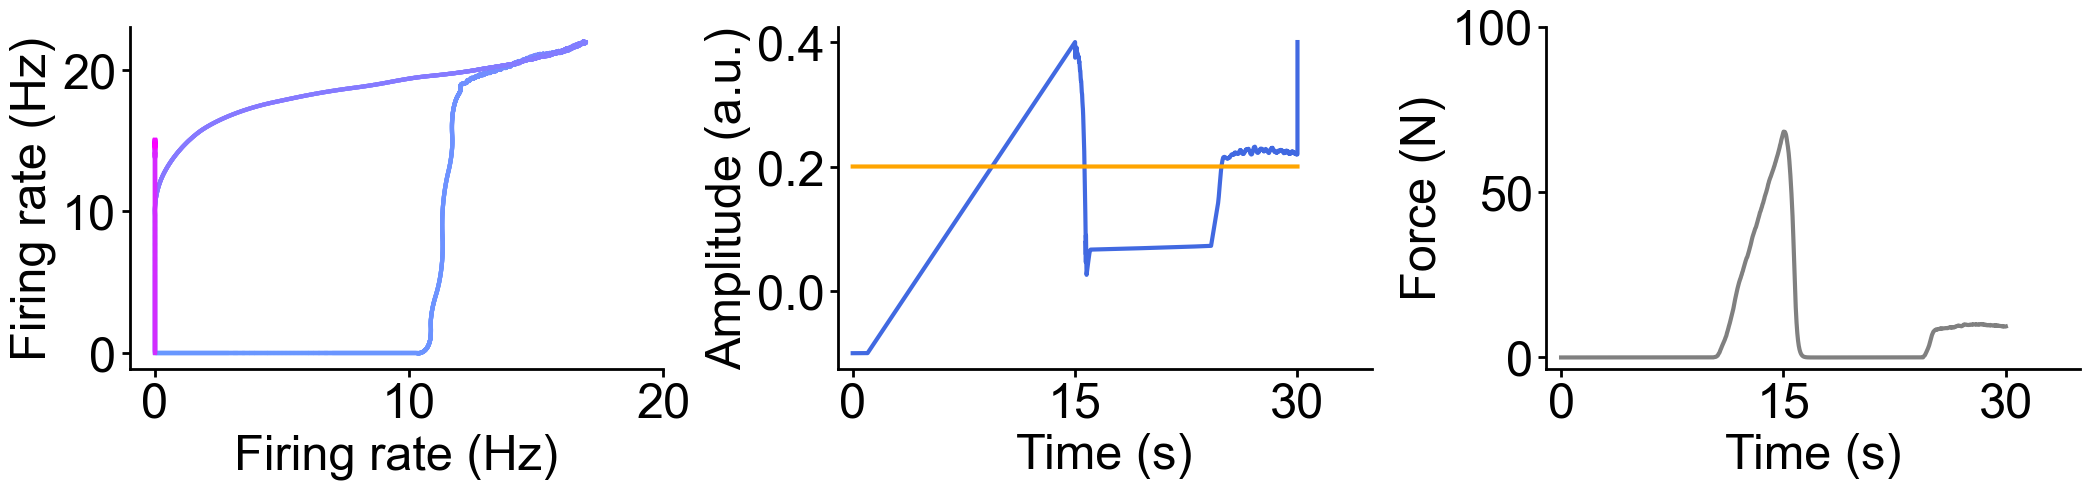

In [8]:
# Set font globally
plt.rcParams['font.family'] = 'Arial'

# Load files
with h5py.File("Data_MN_Model/Data_final/Controller_FINAL_results/exc_TA_MN4551_constant_good.jld2", 'r') as f:
    exc1 = f['tr_new'][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/force_TA_MN4551_constant_good.jld2", 'r') as f:
    force = f['force'][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/inh_TA_MN4551_constant_good.jld2", 'r') as f:
    inh = f['inh_input'][:]

with h5py.File("Data_MN_Model/Data_final/Controller_FINAL_results/trajectory_controlled_TA_MN4551_constant_good.jld2", 'r') as f:
    new = f['trajectory2_controlled'][:]

# Create 1x3 subplot figure
fig, axs = plt.subplots(1, 3, figsize=(21, 5))
cmap = cm.get_cmap('cool', new.shape[1])

# Plot 1: Trajectory in firing rate space
for i in range(new.shape[1] - 1):
    axs[0].plot(new[0, i:i+2], new[1, i:i+2], color=cmap(i / new.shape[1]), linewidth=3)

axs[0].set_xlabel("Firing rate (Hz)", fontsize=35)
axs[0].set_ylabel("Firing rate (Hz)", fontsize=35)
axs[0].tick_params(axis='both', which='major', labelsize=35, width=2, length=6, labelcolor='black')
axs[0].set_xlim(-1, 20)
axs[0].grid(False)

# Plot 2: Excitation and Inhibition
axs[1].plot(exc1, color='royalblue', linewidth=3)
# axs[1].plot(inh * 0.18, color='orange', linewidth=3, alpha=0.5)
axs[1].plot(inh, color='orange', linewidth=3)
axs[1].set_xlabel("Time (s)", fontsize=35)
axs[1].set_ylabel("Amplitude (a.u.)", fontsize=35)
axs[1].tick_params(axis='both', which='major', labelsize=35, width=2, length=6, labelcolor='black')
axs[1].set_xticks([0, 15000, 30000])
axs[1].set_xticklabels(['0', '15', '30'], fontsize=35)

axs[1].set_xlim(-1000, 35000)
axs[1].grid(False)

# Plot 3: Force
axs[2].plot(force, color='gray', linewidth=3)
axs[2].set_xlabel("Time (s)", fontsize=35)
axs[2].set_ylabel("Force (N)", fontsize=35)
axs[2].tick_params(axis='both', which='major', labelsize=35, width=2, length=6, labelcolor='black')
# For the force plot (assuming 20 kHz sampling rate)
axs[2].set_xticks([0, 300000, 600000])
axs[2].set_xticklabels(['0', '15', '30'], fontsize=35)

axs[2].set_xlim(-20000, 700000)
axs[2].set_ylim(top=100)
axs[2].grid(False)

# For the excitation/inhibition plot (assuming 1 kHz sampling rate)

# For the force plot (assuming 20 kHz sampling rate)
axs[2].set_xticks([0, 300000, 600000])
axs[2].set_xticklabels(['0', '15', '30'], fontsize=35)


# Styling
for ax in axs.flat:
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)
    for tick in ax.get_xticklabels():
        tick.set_fontsize(35)
        tick.set_fontweight('normal')
    for tick in ax.get_yticklabels():
        tick.set_fontsize(35)
        tick.set_fontweight('normal')

# Final layout and save
plt.tight_layout()
sns.despine()
plt.savefig('/Users/nmt121/Desktop/Figures/balancedpair4551_3plots_.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
# Parameters
mn1_threshold = 0.1  # Hz, threshold below which MN1 is considered not firing
trajectory = new.copy()
mn1 = trajectory[0, :]
mn2 = trajectory[1, :]

# Logical condition: MN1 nearly zero, and MN2 increasing
mn1_not_firing = mn1 < mn1_threshold
mn2_diff = np.diff(mn2)
mn2_increasing = np.concatenate([[False], mn2_diff > 0])  # Pad to match length

# Both conditions
mn2_alone_increasing = mn1_not_firing & mn2_increasing

# Find contiguous segments
from itertools import groupby
from operator import itemgetter

indices = np.where(mn2_alone_increasing)[0]
segments = []
for k, g in groupby(enumerate(indices), lambda ix: ix[0] - ix[1]):
    group = list(map(itemgetter(1), g))
    if len(group) > 1:
        segments.append(group)

# Compute total time in ms assuming sampling interval (optional - change if you know real time resolution)
dt = 1.0  # 1 ms per sample assumed; adjust if different
total_time_ms = sum(len(seg) * dt for seg in segments)

print(f"MN2 is firing alone and increasing for a total of {total_time_ms:.2f} ms.")

# Optionally annotate on the trajectory plot
axs[0, 0].text(0.05, 0.95, f"MN2 alone ↑: {total_time_ms/1000:.2f} s", 
               transform=axs[0, 0].transAxes,
               fontsize=16, fontweight='bold', color='black',
               verticalalignment='top')


MN2 is firing alone and increasing for a total of 9598.00 ms.


Text(0.05, 0.95, 'MN2 alone ↑: 9.60 s')

## Plot heatmap to understand interaction between Vthca and inhibition

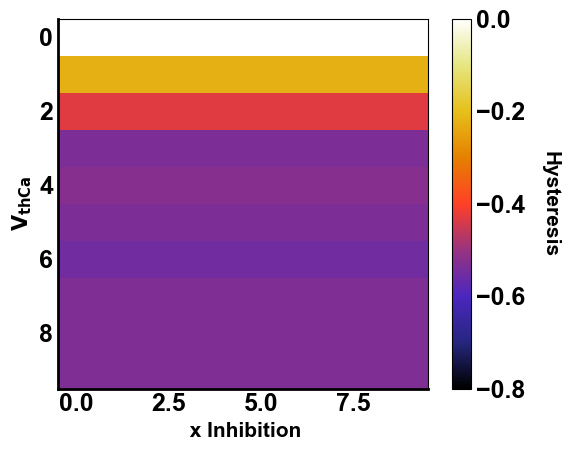

In [86]:
import matplotlib.pyplot as plt
import h5py

# Load the hysteresis data from the .jld2 file
file_path = "Data_MN_Model/Heatmap_values/hysteresis_heatmap1_balanced_FINAL2.jld2"
with h5py.File(file_path, 'r') as f:
    hyst = f['hysteresis_for_each_inh'][:].T

# Set font to Arial and apply consistent styling
plt.rcParams['font.family'] = 'Arial'

# Create the heatmap plot with the CMRmap colormap and set vmin and vmax for color limits
plt.imshow(hyst, cmap='CMRmap', vmin=-0.8, vmax=0)

# Set the x and y labels with the same font size and weight as before
plt.xlabel(" x Inhibition", fontsize=15, fontweight='bold')
plt.ylabel(r"$\mathbf{V_{thCa}}$", fontsize=15)

# Add a colorbar and customize its font size
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=18)

# Set colorbar tick labels to bold
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')

# Customize tick parameters (font size, width, color, and fontweight for bold numbers)
plt.tick_params(axis='both', which='major', labelsize=18, width=2, labelcolor='black')

# Manually set the fontweight of the tick labels to bold
ax = plt.gca()  # Get current axis
for tick in ax.get_xticklabels():
    tick.set_fontweight('bold')
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make axis spines thicker for consistency
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', which='both', length=0)

# Disable grid to match previous plots
plt.grid(False)

# Display the plot
cbar.set_label('Hysteresis', fontsize=15, fontweight='bold', fontname='Arial', rotation=270, labelpad=25)
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)
cbar.ax.tick_params(size=0)  # Set tick size to 0 to remove the small lines

plt.savefig('/Users/nmt121/Desktop/HeatmapMN1_balanced_FINAL.pdf', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()


## Plot flexibility metrics

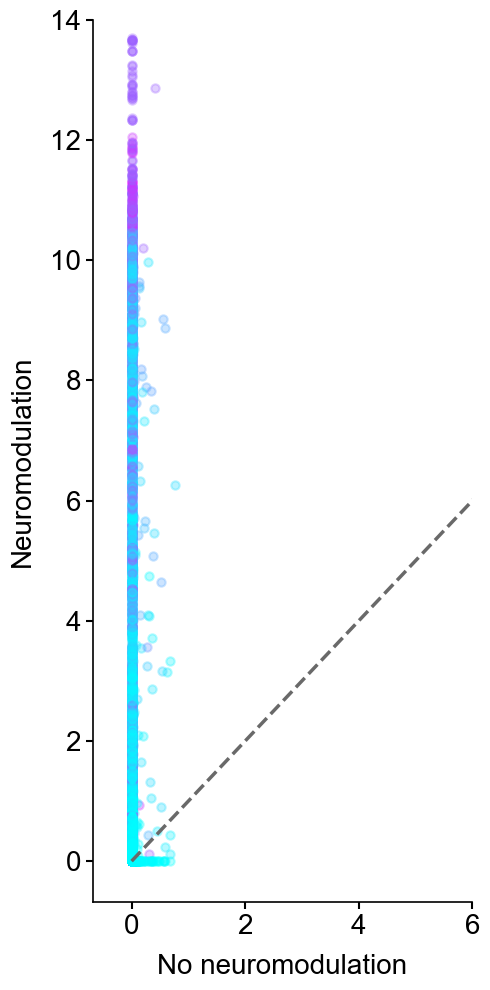

In [184]:
# file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_NOPIC.mat"
# mat_data = scipy.io.loadmat(file_path)
# displacement_NOPIC = mat_data['displacement'][0,:]

# file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_sinusoid_PIC.mat"
# mat_data = scipy.io.loadmat(file_path)
# displacement_PIC = mat_data['displacement'][0,:]


file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_tr_noPIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_NOPIC = mat_data['displacement'][0,:]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/displacement_tr_PIC.mat"
mat_data = scipy.io.loadmat(file_path)
displacement_PIC = mat_data['displacement'][0,:]

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/vthca_sinusoid_PIC_tr.mat" 
# file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/vthca_sinusoid_PIC_trial2.mat"



mat_data = scipy.io.loadmat(file_path)
biophysical_properties = mat_data['different_biophysical_properties'][0,:]
norm = plt.Normalize(vmin=np.min(np.abs(biophysical_properties)), vmax=np.max(np.abs(biophysical_properties)))

max_val = max(np.max(displacement_PIC), np.max(displacement_NOPIC))
min_val = min(np.min(displacement_PIC), np.min(displacement_NOPIC))
fig, ax = plt.subplots(figsize=(5, 10))

plt.plot([min_val, max_val], [min_val, max_val], '--',color='dimgray',label='Diagonal (y = x)', linewidth=2.5)

cmap = plt.cm.cool

# Draw transparent lines between the corresponding points in PIC and NOPIC first
for i in range(len(displacement_NOPIC)):
    color = cmap(norm(abs(biophysical_properties[i])))  # Map the biophysical property to a color
    plt.scatter(displacement_NOPIC[i], displacement_PIC[i], color=color, linewidth=1.5, alpha=0.3)  # Line with gradient color


# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
sns.despine()

# Make axis ticks visible and adjust label size
ax.tick_params(axis='both', which='both', length=5, width=1.5, labelsize=20)

# Set font globally to Arial
plt.rcParams['font.family'] = 'Arial'

# Customize axis line thickness (slightly thinner)
ax.spines['bottom'].set_linewidth(1.2)
ax.spines['left'].set_linewidth(1.2)
ax.set_ylim(top=14)
# Axis labels
ax.set_xlabel('No neuromodulation', fontsize=20, labelpad=10)
ax.set_ylabel('Neuromodulation', fontsize=20, labelpad=10)
ax.set_xlim(right=6)

plt.tight_layout()

plt.savefig('/Users/nmt121/Desktop/Figures/displacement_tr_contraction_PICs.pdf', dpi=300, bbox_inches='tight')

plt.show()







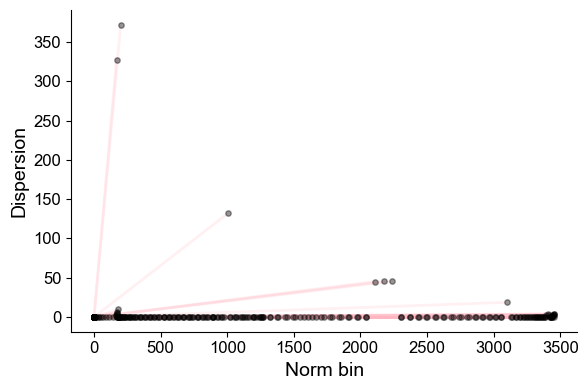

In [ ]:
# Load data
file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/dispersion_sin_PIC.mat"
displacement_NOPIC = scipy.io.loadmat(file_path)['dMNP'][0, :]

file_path = "Data_MN_Model/Data_final/Flexibility_metrics_matlab/normBins_sin_PIC.mat"
normbins = scipy.io.loadmat(file_path)['normBins'][0, :]

# Plot
plt.figure(figsize=(6, 4))
ax = plt.gca()

# Plot each segment as a line
for i in range(len(displacement_NOPIC)):
    plt.plot([0, normbins[i]], [0, displacement_NOPIC[i]], color='lightpink', alpha=0.2, linewidth=2)
    plt.scatter(normbins[i], displacement_NOPIC[i], color='black',alpha=0.4, s=15, zorder=3)

# Styling
plt.xlabel('Norm bin', fontsize=14, fontname='Arial')
plt.ylabel('Dispersion', fontsize=14, fontname='Arial')
plt.xticks(fontsize=12, fontname='Arial')
plt.yticks(fontsize=12, fontname='Arial')

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.grid(False)
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/Figures/dispersion_pic_sin.pdf', dpi=300, bbox_inches='tight')
plt.show()


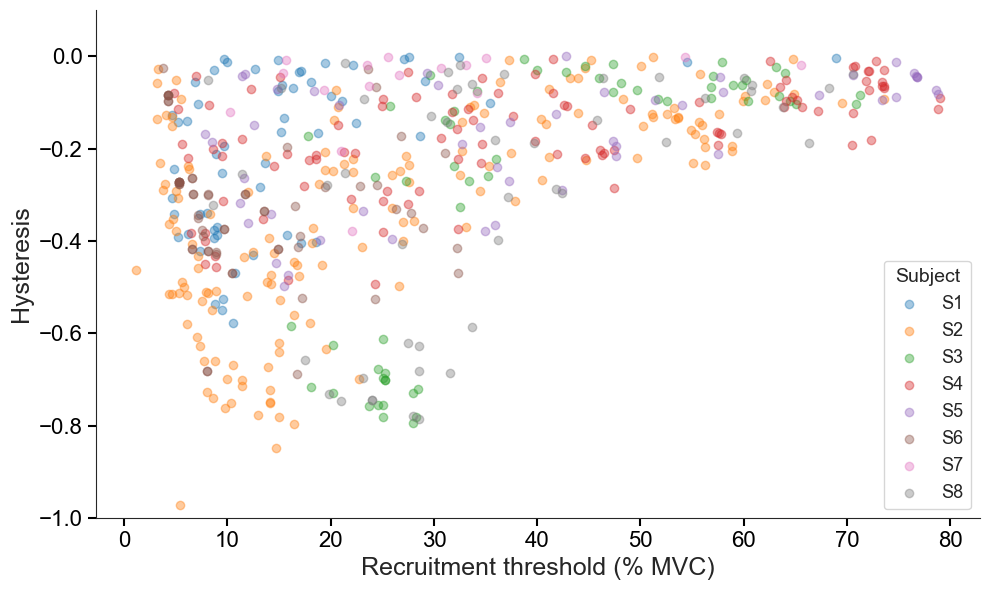

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# === Style settings ===
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 18  # No bold
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['axes.labelweight'] = 'normal'

# === Load and process data ===
def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

dfs = [
    process_data(f'/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_subjects_Avrillonetal/S{i}.csv')
    for i in range(1, 9)
]

# === Optional binning (unused in plot) ===
all_values_hysteresis = np.concatenate([df["hysteresis"] for df in dfs])
all_values_recr = np.concatenate([df.iloc[:, 0] for df in dfs])
combined_df = pd.DataFrame({'force': all_values_recr, 'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')
vals = np.array(sorted_df['hysteresis'])
vals_force = np.array(sorted_df['force'])
d = 10
binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]

# === Custom colors for subjects (change as you like) ===
custom_colors = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#8c564b',  # brown
    '#e377c2',  # pink
    '#7f7f7f'   # gray
]

# === Plot only hysteresis < 0 for each subject ===
# === Plot only hysteresis < 0 for each subject ===
plt.figure(figsize=(10, 6))

for i, df in enumerate(dfs):
    df_neg = df[df['hysteresis'] < 0]
    plt.scatter(df_neg.iloc[:, 0], df_neg['hysteresis'], alpha=0.4, label=f'S{i+1}', color=custom_colors[i])

# === Axis styling ===
plt.ylim(-1, 0.1)
plt.xlabel('Recruitment threshold (% MVC)', fontsize=18)
plt.ylabel('Hysteresis', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()

ax.tick_params(
    axis='both',        # apply to both x and y axes
    which='major',      # major ticks only
    direction='out',    # or 'inout' for both sides
    length=6,           # length of the ticks
    width=1.5,          # thickness of the ticks
    colors='black',     # color of tick lines
    bottom=True,left=True,   # ensure all sides have ticks
)

plt.legend(title="Subject", fontsize=13, title_fontsize=14)
sns.despine()
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/Figures/Experimental_hysteresis.pdf', dpi=300, bbox_inches='tight')

plt.show()




## Plot % success exp data

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_94060/2010171861.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(means.keys(), fontname="Arial", fontsize=15)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_94060/2010171861.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontname="Arial", fontsize=14)


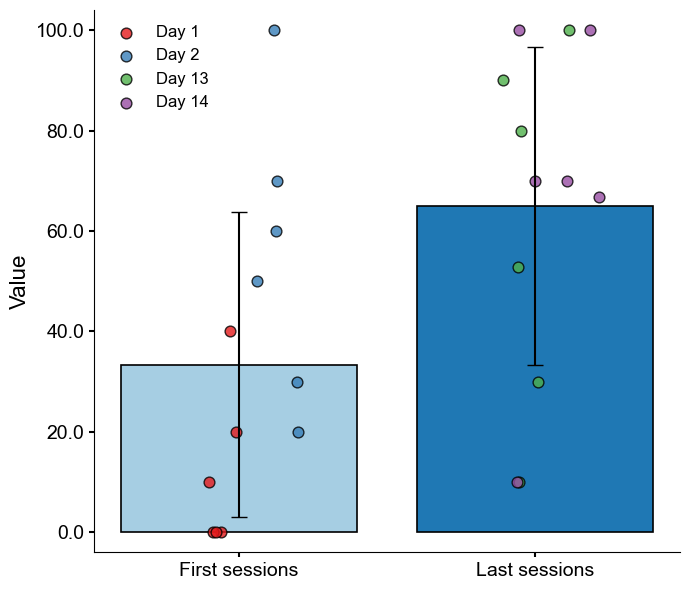

In [4]:
# === Data ===
day1 = [40,20,10,0,0,0]
day2 = [50,60,100,30,70,20]
day13 = [10,90,100,30,80,52.9]
day14 = [100,70,100,66.7,70,10]

first_sessions = day1 + day2
last_sessions  = day13 + day14

# Compute means and stds
means = {
    "First sessions": np.mean(first_sessions),
    "Last sessions": np.mean(last_sessions)
}
stds = {
    "First sessions": np.std(first_sessions),
    "Last sessions": np.std(last_sessions)
}

# === Plot ===
plt.figure(figsize=(7,6))
ax = plt.gca()

# Bar plot
bars = ax.bar(means.keys(), means.values(), 
              yerr=stds.values(),
              capsize=6, color=["#a6cee3","#1f78b4"], 
              edgecolor="black", linewidth=1.2)

# Scatter colors for subgroups
palette = {
    "Day 1":"#e41a1c", 
    "Day 2":"#377eb8",
    "Day 13":"#4daf4a",
    "Day 14":"#984ea3"
}

# Overlay scatter points
x_positions = {"First sessions":0, "Last sessions":1}
jitter = 0.08

# First sessions scatter
ax.scatter(
    np.random.normal(x_positions["First sessions"]-0.05, jitter, len(day1)),
    day1, color=palette["Day 1"], label="Day 1", s=60, alpha=0.8, edgecolor="black"
)
ax.scatter(
    np.random.normal(x_positions["First sessions"]+0.05, jitter, len(day2)),
    day2, color=palette["Day 2"], label="Day 2", s=60, alpha=0.8, edgecolor="black"
)

# Last sessions scatter
ax.scatter(
    np.random.normal(x_positions["Last sessions"]-0.05, jitter, len(day13)),
    day13, color=palette["Day 13"], label="Day 13", s=60, alpha=0.8, edgecolor="black"
)
ax.scatter(
    np.random.normal(x_positions["Last sessions"]+0.05, jitter, len(day14)),
    day14, color=palette["Day 14"], label="Day 14", s=60, alpha=0.8, edgecolor="black"
)

plt.ylim([-4,104])
# === Styling ===
ax.set_ylabel("Value", fontname="Arial", fontsize=16)
ax.set_xticklabels(means.keys(), fontname="Arial", fontsize=15)
ax.set_yticklabels(ax.get_yticks(), fontname="Arial", fontsize=14)

ax.tick_params(axis="both", which="major", labelsize=14, width=1.5)
sns.despine()
ax.legend(frameon=False, fontsize=12)

plt.tight_layout()
# plt.savefig("/Users/nmt121/Desktop/Figures/success_rate_bar.pdf", dpi=300, bbox_inches="tight")
plt.show()
